In [1]:
import glob, pickle, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'
mpl.rcParams['pdf.fonttype'] = 42

In [2]:
stim_dir = './dataFolder/4_RawData_Index_Timestamp/ScaledStimulus/'

# degree moths only (m11 is volts → excluded from angle stats)
deg_files = sorted(glob.glob(stim_dir + '*_timeStamps_degrees.pickle'))

mins, maxs = [], []
for fp in deg_files:
    with open(fp, 'rb') as f:
        wn = np.asarray(pickle.load(f)[2]).ravel()    # index 2 = WhiteNoise (the stimulus, in degrees)
    mins.append(wn.min())
    maxs.append(wn.max())
    print(f'{os.path.basename(fp)}: {wn.min():.3f} to {wn.max():.3f} deg')

print(f'\nAngle range (degrees), n={len(deg_files)} moths:')
print(f'  global min {min(mins):.3f}')
print(f'  global max {max(maxs):.3f}')

m20_wn2_timeStamps_degrees.pickle: -16.350 to 20.163 deg
m23_wn2_timeStamps_degrees.pickle: -26.378 to 31.315 deg
m29_wn2_timeStamps_degrees.pickle: -21.425 to 23.796 deg
m30_wn1_timeStamps_degrees.pickle: -23.801 to 28.185 deg
m31_wn2_timeStamps_degrees.pickle: -21.344 to 23.952 deg

Angle range (degrees), n=5 moths:
  global min -26.378
  global max 31.315


In [5]:
out_path = './dataFolder/5_1DCompModel/Unscaled_clippedNLD/forForwardPrediction/v2/selectedUnits/'
deg_amp, volt_amp = [], []     # max-magnitude deflection per unit
records = []
for fp in sorted(glob.glob(out_path + '*_EncodingModel.pickle')):
    fname = os.path.basename(fp)
    with open(fp, 'rb') as f:
        sta = np.asarray(pickle.load(f)[1]).ravel()    # index 1 = STA
    pre = sta[:600]                                    # pre-spike only
    amp = np.abs(pre).max()                            # largest deflection, neg or pos
    mothID = "_".join(fname.split('_')[0:3])
    if fname.startswith('m11'):
        volt_amp.append(amp)
        group = 'volts'
    else:
        deg_amp.append(amp)
        group = 'degrees'
    records.append({'mothID': mothID, 'sta_max_amplitude': amp, 'group': group})
    print(f'{fname}: max amplitude {amp:.4f}')
deg_amp, volt_amp = np.array(deg_amp), np.array(volt_amp)
print(f'\nSTA max amplitude — DEGREES group, n={len(deg_amp)} units:')
print(f'  mean {deg_amp.mean():.4f}   std {deg_amp.std(ddof=1):.4f}')
print(f'\nSTA max amplitude — VOLTS group (m11), n={len(volt_amp)} units:')
print(f'  mean {volt_amp.mean():.4f}   std {volt_amp.std(ddof=1):.4f}')

os.makedirs('./dataFolder/SummaryValuesFinal', exist_ok=True); pd.DataFrame(records).to_csv('./dataFolder/SummaryValuesFinal/STA_anglerangeabs.csv', index=False)

m11_unit_1_EncodingModel.pickle: max amplitude 1.0826
m11_unit_2_EncodingModel.pickle: max amplitude 1.8684
m11_unit_3_EncodingModel.pickle: max amplitude 1.8223
m23_unit_1_EncodingModel.pickle: max amplitude 8.1698
m29_unit_1_EncodingModel.pickle: max amplitude 9.7719
m29_unit_2_EncodingModel.pickle: max amplitude 11.0111
m29_unit_3_EncodingModel.pickle: max amplitude 13.4074
m30_unit_1_EncodingModel.pickle: max amplitude 9.7329
m30_unit_2_EncodingModel.pickle: max amplitude 9.6241
m31_unit_1_EncodingModel.pickle: max amplitude 5.8399
m31_unit_2_EncodingModel.pickle: max amplitude 10.9769
m31_unit_3_EncodingModel.pickle: max amplitude 7.8716

STA max amplitude — DEGREES group, n=9 units:
  mean 9.6006   std 2.1680

STA max amplitude — VOLTS group (m11), n=3 units:
  mean 1.5911   std 0.4410


In [6]:
import statistics

values = [1.70, 0.03, 0.87, 0.60, 1.03, 1.13, 1.33, 1.23]

std_dev = statistics.stdev(values)
print(f"Sample Standard Deviation: {std_dev:.2f}")


Sample Standard Deviation: 0.51


In [7]:
lat = pd.read_csv('./dataFolder/5b_Latency/selectedUnits/time_to_spike.csv')
latency_ms = lat['merged'].values * 1000          # merged = time_up where it exists, else time_down
print(f'Latency (ms), n={len(latency_ms)} units:')
print(f'  mean   {np.mean(latency_ms):.3f}')
print(f'  std    {np.std(latency_ms, ddof=1):.3f}')
print(f'  median {np.median(latency_ms):.3f}')
print(f'  min    {np.min(latency_ms):.3f}')
print(f'  max    {np.max(latency_ms):.3f}')
print(f'  25th   {np.percentile(latency_ms, 25):.3f}')
print(f'  75th   {np.percentile(latency_ms, 75):.3f}')

lat['latency_ms'] = latency_ms; os.makedirs('./dataFolder/SummaryValuesFinal', exist_ok=True); lat.to_csv('./dataFolder/SummaryValuesFinal/timetospike_summary.csv', index=False)

Latency (ms), n=12 units:
  mean   2.003
  std    0.851
  median 1.900
  min    0.767
  max    4.033
  25th   1.483
  75th   2.367


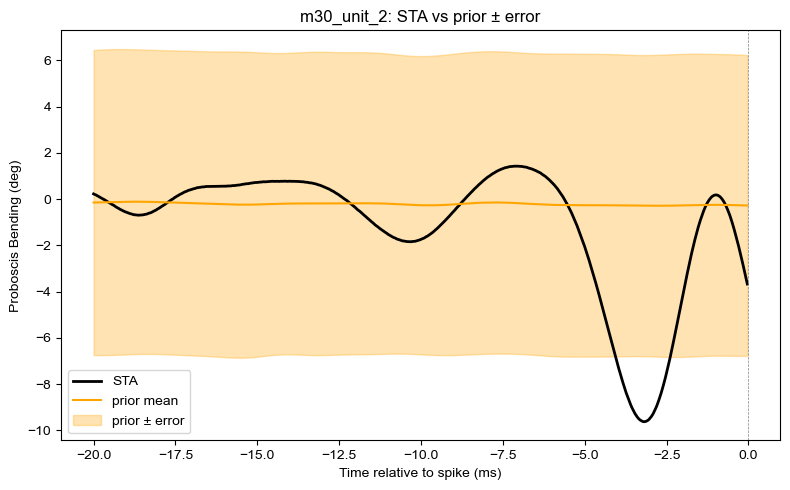

up crossings (sample idx from start): none
down crossings (sample idx from start): [479 480 481 482 483]
first down crossing: 4.033 ms before spike


In [10]:
moth_unit_id = 'm30_unit_2'   # change this to whichever unit you want to check

fp = [f for f in glob.glob('./dataFolder/5_1DCompModel/UnscaledFiringRate_NLD/v2/*_EncodingModel.pickle')
      if moth_unit_id in f][0]

with open(fp, 'rb') as f:
    d = pickle.load(f)

sta = np.asarray(d[1]).ravel()
prior_mean = np.asarray(d[4]).ravel()
prior_error = np.asarray(d[5]).ravel()

pre_sta = sta[:600]
pre_prior = prior_mean[:600]
pre_error = prior_error[:600]

t_ms = np.arange(-600, 0) / 30e3 * 1000   # matches Fs=3e4, 600 pre-spike samples

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t_ms, pre_sta, 'k', linewidth=2, label='STA')
ax.plot(t_ms, pre_prior, 'orange', linewidth=1.5, label='prior mean')
ax.fill_between(t_ms, pre_prior - pre_error, pre_prior + pre_error,
                color='orange', alpha=0.3, label='prior ± error')
ax.axvline(0, color='grey', ls='--', lw=0.5)
ax.set_xlabel('Time relative to spike (ms)')
ax.set_ylabel('Proboscis Bending (deg)')
ax.set_title(f'{moth_unit_id}: STA vs prior ± error')
ax.legend()
plt.tight_layout()
plt.show()

# print where the STA actually crosses the prior band, same logic as 6b/3aa
up = np.where(pre_sta > pre_prior + pre_error)[0]
down = np.where(pre_sta < pre_prior - pre_error)[0]
print('up crossings (sample idx from start):', up[:5] if len(up) else 'none')
print('down crossings (sample idx from start):', down[:5] if len(down) else 'none')
if len(down):
    print(f'first down crossing: {(600 - down[0])/30e3*1000:.3f} ms before spike')
if len(up):
    print(f'first up crossing: {(600 - up[0])/30e3*1000:.3f} ms before spike')